In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import eclipsr as ecl

import time
from pathlib import Path
from astropy.io import fits

import lightkurve as lk

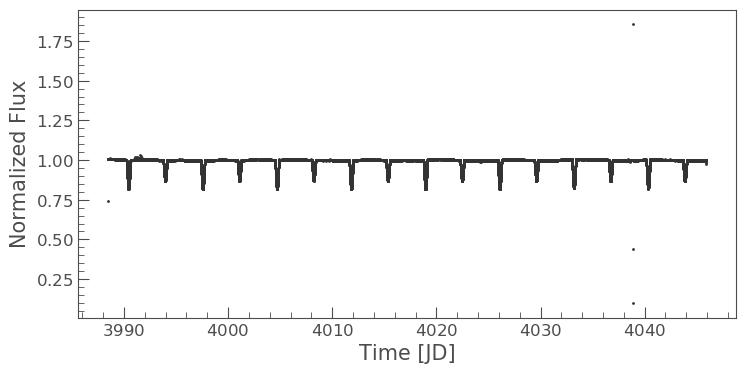

In [32]:
path = sorted(Path('../lightcurves/tic_1449121').rglob('*.fits'))[0]

with fits.open(path) as hdul:
    d = hdul[1].data
    t = np.asarray(d['TIME'], dtype=float)
    f = np.asarray(d['SAP_FLUX'], dtype=float)
    q = np.asarray(d['QUALITY']) == 0

good =  np.isfinite(t) & np.isfinite(f)
t, f = t[good], f[good]

lc = lk.LightCurve(time=t, flux=f).remove_nans().normalize()
lc.scatter();

In [33]:
from scipy.signal import medfilt

f_med = medfilt(f, 5)                     # 5 noktalık medyan: ≥3 noktalı yapıları korur
resid = f - f_med
sig = 1.4826 * np.median(np.abs(resid - np.median(resid)))
keep = np.abs(resid) < 5 * sig
print(f'{(~keep).sum()} aykırı nokta atıldı')
t, f = t[keep], f[keep]

160 aykırı nokta atıldı


In [34]:
times, flux = ecl.utility.ingest_signal(t, f, tess_sectors=False)

result = ecl.find_eclipses(times, flux, mode=2, tess_sectors=False)
t_0, period, score, sine_like, wide, n_kernel, width_stats, depth_stats, ecl_mid, widths, depths, ratios, added_snr, ecl_indices, flags_lrf, flags_pst = result

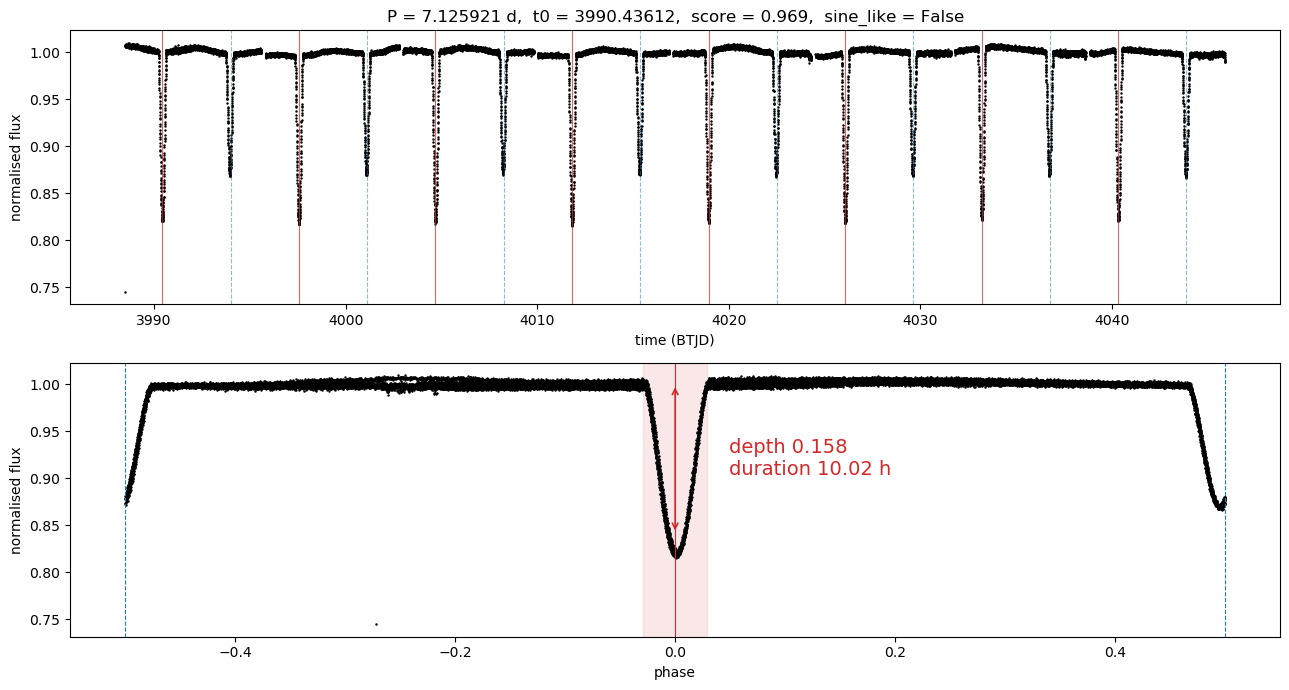

In [35]:
dur_pri   = width_stats[0, 0]
depth_pri = depth_stats[0, 0]

fig, ax = plt.subplots(2, 1, figsize=(13, 7))

# --- 1. zaman serisi ---
ax[0].plot(t, f, '.', ms=1.5, color='k')
n0 = int(np.floor((times.min() - t_0) / period))
n1 = int(np.ceil((times.max() - t_0) / period))
for n in range(n0, n1 + 1):
    tp = t_0 + n * period
    if times.min() <= tp <= times.max():
        ax[0].axvline(tp, color='tab:red', lw=0.8, alpha=0.7)
        ax[0].axvline(tp + period / 2, color='tab:blue', lw=0.8,
                      alpha=0.5, ls='--')
ax[0].set_xlabel('time (BTJD)')
ax[0].set_ylabel('normalised flux')
ax[0].set_title(f'P = {period:.6f} d,  t0 = {t_0:.5f},  '
                f'score = {score:.3f},  sine_like = {sine_like}')

# --- 2. katlanmış eğri, birincil derinlik ve süre ---
phase = ((times - t_0) / period + 0.5) % 1 - 0.5
o = np.argsort(phase)
ax[1].plot(phase[o], flux[o], '.', ms=1.5, color='k')
ax[1].axvline(0, color='tab:red', lw=0.8)
ax[1].axvline(0.5, color='tab:blue', lw=0.8, ls='--')
ax[1].axvline(-0.5, color='tab:blue', lw=0.8, ls='--')

base = np.median(flux)
dur_ph = dur_pri / period
ax[1].axvspan(-dur_ph / 2, dur_ph / 2, color='tab:red', alpha=0.10)
ax[1].annotate('', xy=(0, base * (1 - depth_pri)), xytext=(0, base),
               arrowprops=dict(arrowstyle='<->', color='tab:red', lw=1.2))
ax[1].text(dur_ph / 2 + 0.02, base * (1 - depth_pri / 2),
           f'depth {depth_pri:.3f}\nduration {dur_pri * 24:.2f} h',
           color='tab:red', va='center', fontsize=14)

ax[1].set_xlabel('phase')
ax[1].set_ylabel('normalised flux')

plt.tight_layout(); plt.show()

In [23]:
dur_pri, depth_pri

(0.41753189102877286, 0.1583981434429984)

In [36]:
lrf, pst = np.asarray(flags_lrf), np.asarray(flags_pst)
full_pri = (lrf == 0) & (pst == 1)

dur_obs, dep_obs = [], []
for k in np.flatnonzero(full_pri):
    i1, i2, i3, i4 = ecl_indices[k]
    bottom = np.median(flux[i2:i3+1]) if i3 > i2 else flux[i2]
    base   = np.median(np.r_[flux[i1-5:i1], flux[i4+1:i4+6]])
    dur_obs.append(times[i4] - times[i1])
    dep_obs.append(1 - bottom / base)

dur_obs, dep_obs = np.array(dur_obs), np.array(dep_obs)
print(f'ECLIPSR : depth {depth_stats[0,0]:.4f}  süre {width_stats[0,0]*24:.2f} sa')
print(f'akıdan  : depth {dep_obs.mean():.4f} ± {dep_obs.std():.4f}'
      f'süre {dur_obs.mean()*24:.2f} ± {dur_obs.std()*24:.2f} sa')
print(f'oran    : {depth_stats[0,0]/dep_obs.mean():.3f}')

ECLIPSR : depth 0.1584  süre 10.02 sa
akıdan  : depth 0.1804 ± 0.0013süre 10.02 ± 0.06 sa
oran    : 0.878


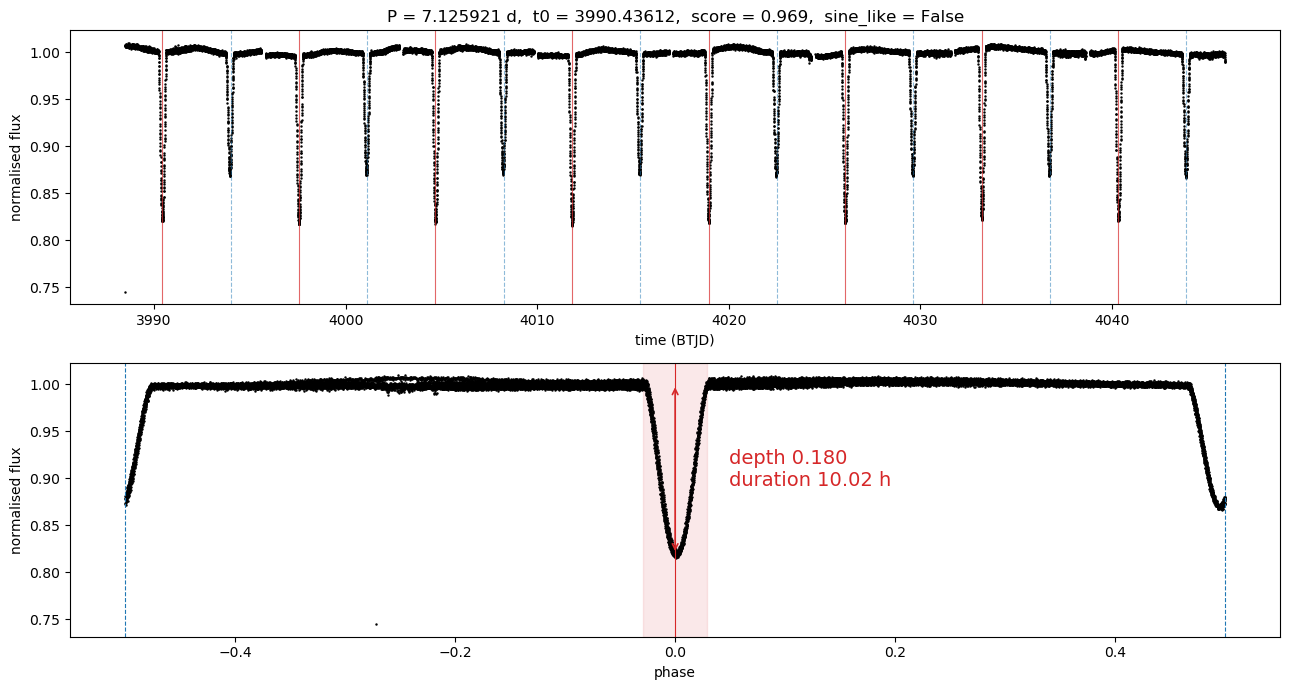

In [37]:
dur_pri   = dur_obs.mean()
depth_pri = dep_obs.mean()

fig, ax = plt.subplots(2, 1, figsize=(13, 7))

# --- 1. zaman serisi ---
ax[0].plot(t, f, '.', ms=1.5, color='k')
n0 = int(np.floor((times.min() - t_0) / period))
n1 = int(np.ceil((times.max() - t_0) / period))
for n in range(n0, n1 + 1):
    tp = t_0 + n * period
    if times.min() <= tp <= times.max():
        ax[0].axvline(tp, color='tab:red', lw=0.8, alpha=0.7)
        ax[0].axvline(tp + period / 2, color='tab:blue', lw=0.8,
                      alpha=0.5, ls='--')
ax[0].set_xlabel('time (BTJD)')
ax[0].set_ylabel('normalised flux')
ax[0].set_title(f'P = {period:.6f} d,  t0 = {t_0:.5f},  '
                f'score = {score:.3f},  sine_like = {sine_like}')

# --- 2. katlanmış eğri, birincil derinlik ve süre ---
phase = ((times - t_0) / period + 0.5) % 1 - 0.5
o = np.argsort(phase)
ax[1].plot(phase[o], flux[o], '.', ms=1.5, color='k')
ax[1].axvline(0, color='tab:red', lw=0.8)
ax[1].axvline(0.5, color='tab:blue', lw=0.8, ls='--')
ax[1].axvline(-0.5, color='tab:blue', lw=0.8, ls='--')

base = np.median(flux)
dur_ph = dur_pri / period
ax[1].axvspan(-dur_ph / 2, dur_ph / 2, color='tab:red', alpha=0.10)
ax[1].annotate('', xy=(0, base * (1 - depth_pri)), xytext=(0, base),
               arrowprops=dict(arrowstyle='<->', color='tab:red', lw=1.2))
ax[1].text(dur_ph / 2 + 0.02, base * (1 - depth_pri / 2),
           f'depth {depth_pri:.3f}\nduration {dur_pri * 24:.2f} h',
           color='tab:red', va='center', fontsize=14)

ax[1].set_xlabel('phase')
ax[1].set_ylabel('normalised flux')

plt.tight_layout(); plt.show()